In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report , accuracy_score, confusion_matrix)
import seaborn as sns

In [2]:
df = pd.read_csv("bedtime_screentime_sleep_debt.csv")

In [3]:
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [5]:
df.describe()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000,3.794671
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407,2.685153
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000,1.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000,1.100000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000,3.200000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000,5.600000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000,10.000000


In [6]:
text_cols = ["gender", "occupation_type", "chronotype", "primary_bedtime_app"]

overview = pd.DataFrame({
    "column": text_cols,
    "n_categories": [df[c].nunique() for c in text_cols],
    "categories": [" | ".join(sorted(df[c].unique())) for c in text_cols],
})
overview

,column,n_categories,categories
0,gender,3,Female | Male | Non-Binary
1,occupation_type,5,Corporate 9-to-5 | Freelance / Creative | Heal...
2,chronotype,3,Intermediate | Morning Lark | Night Owl
3,primary_bedtime_app,6,Instagram / Reddit | Messaging / Chat | News /...


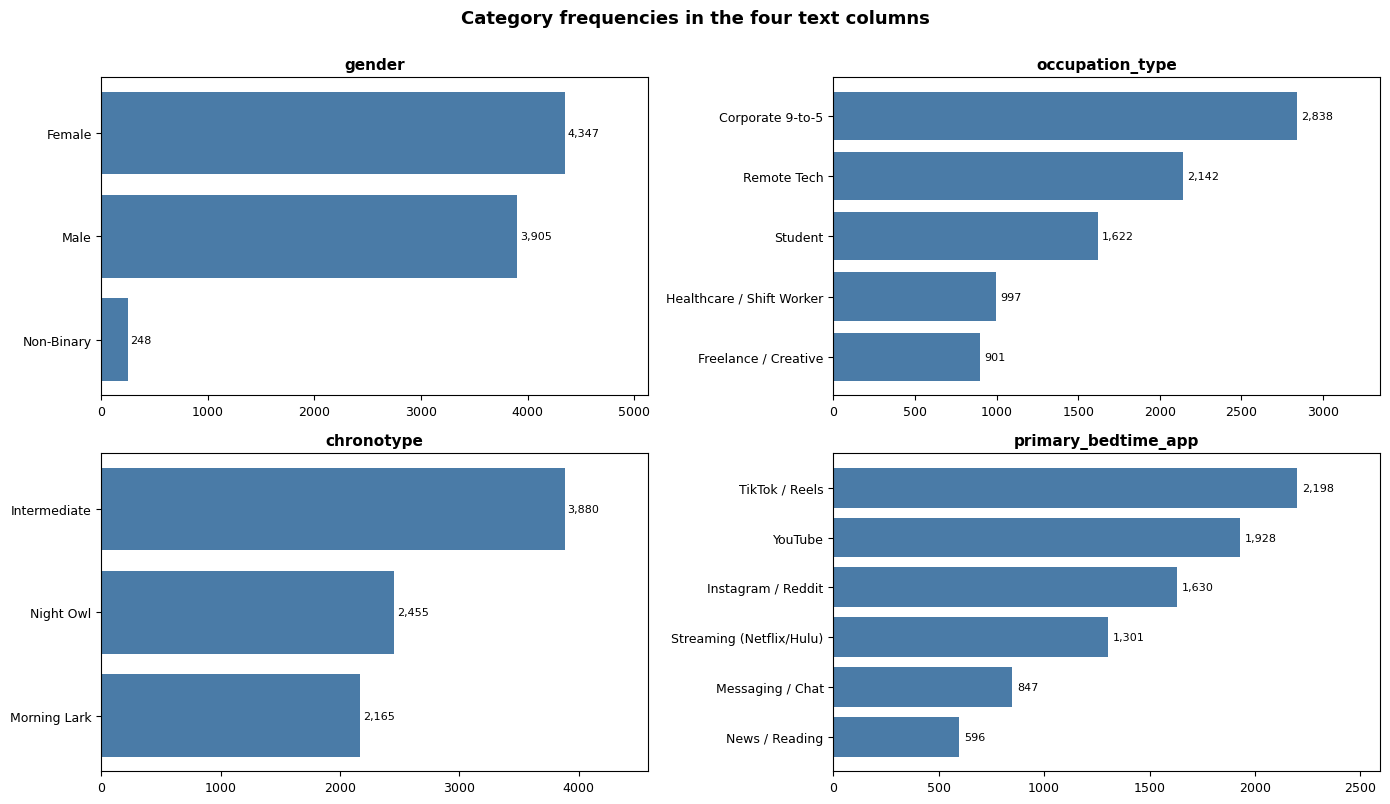

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), text_cols):
    vc = df[col].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color="#4a7ba7")
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v + 25, i, f"{v:,}", va="center", fontsize=8)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlim(0, vc.max() * 1.18)
    ax.tick_params(labelsize=9)
fig.suptitle("Category frequencies in the four text columns",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

In [8]:
CHRONOTYPE_RANK = {
    "Morning Lark": 0,
    "Intermediate": 1,
    "Night Owl": 2,
}

df_enc = df.copy()
df_enc["chronotype_rank"] = df_enc["chronotype"].map(CHRONOTYPE_RANK)

# Any unmapped value would become NaN - check before moving on.
assert df_enc["chronotype_rank"].notna().all(), "unmapped chronotype value found"

print(df_enc[["chronotype", "chronotype_rank"]].drop_duplicates().sort_values("chronotype_rank"))

     chronotype  chronotype_rank
7  Morning Lark                0
0  Intermediate                1
2     Night Owl                2


In [9]:
onehot_cols = ["gender", "occupation_type", "primary_bedtime_app"]

dummies = pd.get_dummies(
    df_enc[onehot_cols],
    drop_first=True,
).astype(int)        # get_dummies gives bool; cast to int so coefficients read cleanly

print(f"{len(onehot_cols)} columns -> {dummies.shape[1]} dummy columns\n")
for col in onehot_cols:
    produced = [c for c in dummies.columns if c.startswith(col + "_")]
    baseline = sorted(set(df_enc[col].unique()) - {c[len(col) + 1:] for c in produced})
    print(f"{col}")
    print(f"   baseline (dropped): {baseline[0]}")
    print(f"   kept as columns   : {[c for c in produced]}")
print()
dummies.head()

3 columns -> 11 dummy columns

gender
   baseline (dropped): Female
   kept as columns   : ['gender_Male', 'gender_Non-Binary']
occupation_type
   baseline (dropped): Corporate 9-to-5
   kept as columns   : ['occupation_type_Freelance / Creative', 'occupation_type_Healthcare / Shift Worker', 'occupation_type_Remote Tech', 'occupation_type_Student']
primary_bedtime_app
   baseline (dropped): Instagram / Reddit
   kept as columns   : ['primary_bedtime_app_Messaging / Chat', 'primary_bedtime_app_News / Reading', 'primary_bedtime_app_Streaming (Netflix/Hulu)', 'primary_bedtime_app_TikTok / Reels', 'primary_bedtime_app_YouTube']



,gender_Male,gender_Non-Binary,occupation_type_Freelance / Creative,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,0,0,0,1,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,1
2,0,0,0,1,0,0,0,0,0,1,0
3,0,1,0,0,1,0,0,0,0,0,1
4,0,0,0,1,0,0,0,0,0,1,0


In [10]:
TARGET = "sleep_debt_category"
ID_COLS = ["user_id"]

In [14]:
numeric_cols = [
    c for c in df.columns
    if c not in ID_COLS + text_cols + [TARGET]
    and df[c].dtype != "object"
]

X = pd.concat(
    [
        df_enc[numeric_cols],              # 11 - identical to Notebook 1
        df_enc[["chronotype_rank"]],       #  1 - ordinal
        dummies,                           # 11 - one-hot
    ],
    axis=1,
)
Y = df_enc[TARGET].copy()

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25)

In [16]:
model = LogisticRegression()

In [17]:
model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [18]:
model.fit(X_train, Y_train)

c:\Users\chris\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [20]:
Y_predict = model.predict(X_test)

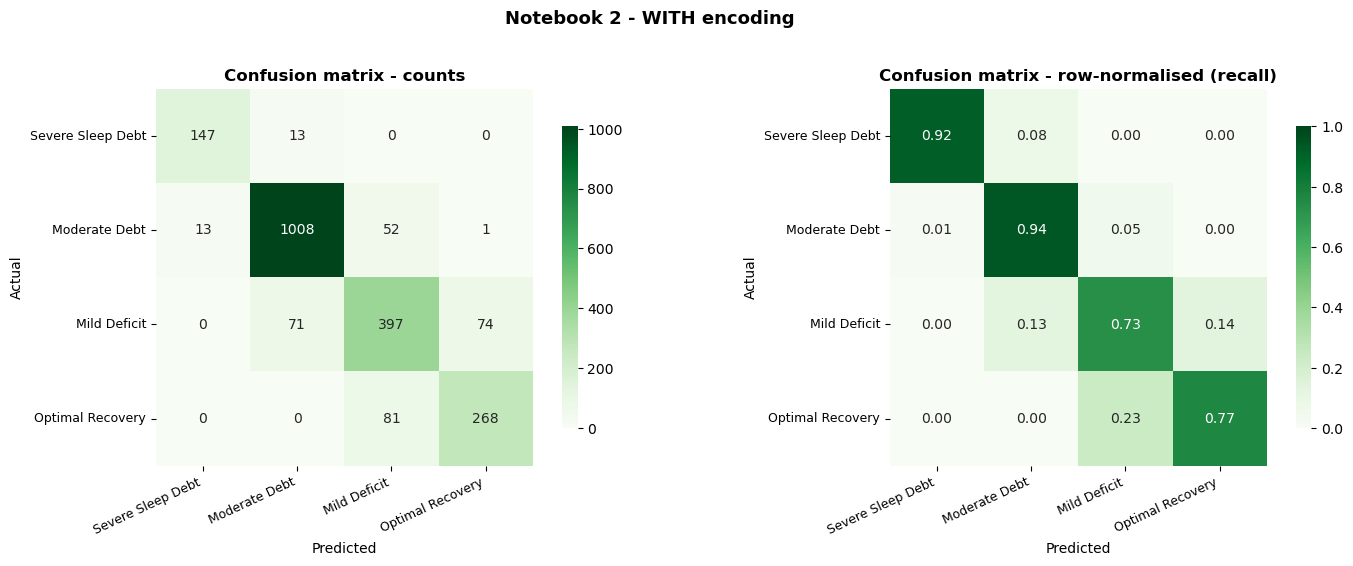

In [22]:
CLASS_ORDER = ["Severe Sleep Debt", "Moderate Debt", "Mild Deficit", "Optimal Recovery"]

cm = confusion_matrix(Y_test, Y_predict, labels=CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", square=True,
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[0],
            cbar_kws={"shrink": 0.8})
axes[0].set_title("Confusion matrix - counts", fontsize=12, fontweight="bold")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", square=True, vmin=0, vmax=1,
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[1],
            cbar_kws={"shrink": 0.8})
axes[1].set_title("Confusion matrix - row-normalised (recall)", fontsize=12, fontweight="bold")

for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right", fontsize=9)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

fig.suptitle("Notebook 2 - WITH encoding", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [23]:
print(classification_report(Y_test, Y_predict, labels=CLASS_ORDER, digits=3))

                   precision    recall  f1-score   support

Severe Sleep Debt      0.919     0.919     0.919       160
    Moderate Debt      0.923     0.939     0.931      1074
     Mild Deficit      0.749     0.732     0.741       542
 Optimal Recovery      0.781     0.768     0.775       349

         accuracy                          0.856      2125
        macro avg      0.843     0.839     0.841      2125
     weighted avg      0.855     0.856     0.856      2125

